# AI5707 – Assignment 7: GMM Models and Pattern Recognition

This notebook uses:
- **Part 1:** the Gaussian-mixture data-generation method and parameters from my Lab 6, followed by GMM classification as required in Assignment 7.
- **Part 2:** the already-separated digit datasets in `data/train`, `data/dev`, and `data/test` for digits **0, 1, and 4**.

## 1. Imports, manual LCG, Box–Muller, and GMM implementation

In [1]:
from pathlib import Path
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# MANUAL RANDOM-NUMBER GENERATION (same LCG method as Lab 6)
_lcg_seed = 19283728

def reset_generator(seed_value=19283728):
    global _lcg_seed
    _lcg_seed = int(seed_value)

def generator():
    """LCG: x(n+1) = (a*x(n) + c) mod m; returns U in [0, 1)."""
    global _lcg_seed
    a, c, m = 1103515245, 12345, 2**31
    _lcg_seed = (a * _lcg_seed + c) % m
    return _lcg_seed / m

def uniform(low=0.0, high=1.0, size=1):
    """Generate uniform values using only the manual LCG."""
    return np.asarray(
        [low + (high - low) * generator() for _ in range(size)],
        dtype=float
    )

def normal_pair():
    """Box-Muller transform: two standard-normal values from two LCG uniforms."""
    u1 = uniform()[0]
    u2 = uniform()[0]
    while u1 <= 0.0:
        u1 = uniform()[0]
    radius = math.sqrt(-2.0 * math.log(u1))
    angle = 2.0 * math.pi * u2
    return radius * math.cos(angle), radius * math.sin(angle)

def choose_component(weights):
    """Select a Gaussian component using cumulative mixture weights."""
    u = uniform()[0]
    cumulative = 0.0
    for index, weight in enumerate(weights):
        cumulative += weight
        if u < cumulative:
            return index
    return len(weights) - 1

def make_point(mean, cov):
    """Generate a 2D Gaussian point using the Lab 6 covariance transform."""
    z1, z2 = normal_pair()
    a, b, c = cov[0][0], cov[0][1], cov[1][1]
    x = mean[0] + math.sqrt(a) * z1
    y = mean[1] + (b / math.sqrt(a)) * z1
    y += math.sqrt(c - (b * b / a)) * z2
    return [x, y]

def generate_class(n, weights, means, covariances):
    points, component_ids = [], []
    for _ in range(n):
        component = choose_component(weights)
        points.append(make_point(means[component], covariances[component]))
        component_ids.append(component)
    return points, component_ids

# ------------------------------------------------------------------
# GMM implementation using the Expectation-Maximization (EM) algorithm
# Deterministic farthest-first initialization; no random initialization.
# Supports diagonal and full covariance matrices.
# ------------------------------------------------------------------
def _logsumexp(a, axis=1):
    a_max = np.max(a, axis=axis, keepdims=True)
    result = a_max + np.log(np.sum(np.exp(a - a_max), axis=axis, keepdims=True))
    return np.squeeze(result, axis=axis)

class GMM:
    def __init__(self, K=3, covariance_type="diag", reg=1e-5,
                 max_iter=100, tol=1e-4):
        if K < 1:
            raise ValueError("K must be at least 1.")
        if covariance_type not in ("full", "diag"):
            raise ValueError("covariance_type must be 'full' or 'diag'.")
        self.K = K
        self.covariance_type = covariance_type
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.means = None
        self.covariances = None
        self.log_likelihoods = []
        self.initial_indices = None

    def _deterministic_initial_means(self, X):
        n, _ = X.shape
        if self.K > n:
            raise ValueError("K cannot exceed the number of training samples.")
        global_mean = np.mean(X, axis=0)
        first = int(np.argmin(np.sum((X - global_mean) ** 2, axis=1)))
        chosen = [first]
        min_dist = np.sum((X - X[first]) ** 2, axis=1)
        min_dist[first] = -1.0
        while len(chosen) < self.K:
            nxt = int(np.argmax(min_dist))
            chosen.append(nxt)
            d2 = np.sum((X - X[nxt]) ** 2, axis=1)
            min_dist = np.minimum(min_dist, d2)
            min_dist[chosen] = -1.0
        self.initial_indices = chosen
        return X[chosen].copy()

    def _initialize(self, X):
        n, d = X.shape
        self.means = self._deterministic_initial_means(X)
        self.weights = np.full(self.K, 1.0 / self.K)
        if self.covariance_type == "diag":
            variance = np.var(X, axis=0) + self.reg
            self.covariances = np.tile(variance, (self.K, 1))
        else:
            covariance = np.atleast_2d(np.cov(X, rowvar=False))
            covariance += self.reg * np.eye(d)
            self.covariances = np.tile(covariance, (self.K, 1, 1))

    def _estimate_log_prob(self, X):
        n, d = X.shape
        log_prob = np.empty((n, self.K))
        for k in range(self.K):
            if self.covariance_type == "diag":
                var = np.maximum(self.covariances[k], self.reg)
                diff = X - self.means[k]
                log_det = np.sum(np.log(var))
                quad = np.sum((diff * diff) / var, axis=1)
            else:
                cov = self.covariances[k] + self.reg * np.eye(d)
                sign, log_det = np.linalg.slogdet(cov)
                if sign <= 0:
                    cov = cov + (10 * self.reg) * np.eye(d)
                    sign, log_det = np.linalg.slogdet(cov)
                diff = X - self.means[k]
                solved = np.linalg.solve(cov, diff.T).T
                quad = np.sum(diff * solved, axis=1)
            log_prob[:, k] = -0.5 * (
                d * np.log(2.0 * np.pi) + log_det + quad
            )
        return log_prob

    def score_samples(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        weighted = self._estimate_log_prob(X) + np.log(
            np.maximum(self.weights, 1e-12)
        )
        return _logsumexp(weighted, axis=1)

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or not np.all(np.isfinite(X)):
            raise ValueError("X must be a finite 2D array.")
        if len(X) < self.K:
            raise ValueError(f"Need at least K={self.K} training samples.")
        self._initialize(X)
        previous_ll = None
        self.log_likelihoods = []
        for _ in range(self.max_iter):
            weighted = self._estimate_log_prob(X) + np.log(
                np.maximum(self.weights, 1e-12)
            )
            log_norm = _logsumexp(weighted, axis=1)
            resp = np.exp(weighted - log_norm[:, None])
            self.log_likelihoods.append(float(np.mean(log_norm)))

            nk = resp.sum(axis=0) + 1e-10
            self.weights = nk / nk.sum()
            self.means = (resp.T @ X) / nk[:, None]

            if self.covariance_type == "diag":
                new_cov = np.empty((self.K, X.shape[1]))
                for k in range(self.K):
                    diff = X - self.means[k]
                    new_cov[k] = (
                        resp[:, k, None] * diff * diff
                    ).sum(axis=0) / nk[k]
                    new_cov[k] = np.maximum(new_cov[k], self.reg)
            else:
                d = X.shape[1]
                new_cov = np.empty((self.K, d, d))
                for k in range(self.K):
                    diff = X - self.means[k]
                    weighted_diff = diff * np.sqrt(resp[:, k, None])
                    new_cov[k] = (weighted_diff.T @ weighted_diff) / nk[k]
                    new_cov[k] += self.reg * np.eye(d)
            self.covariances = new_cov

            current_ll = self.log_likelihoods[-1]
            if previous_ll is not None and abs(current_ll - previous_ll) < self.tol:
                break
            previous_ll = current_ll
        return self

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
print("Project directory:", PROJECT_DIR)
print("Data folder found:", DATA_DIR.is_dir())


Project directory: c:\Users\user\Documents
Data folder found: True


## Part 1 – GMM classification on data generated using my Lab 6 method

The parameters below are retained from Lab 6: 2,500 points per class, three Gaussian components, the original class weights and means, and the Spherical, Diagonal, and Full covariance matrices.

For Assignment 7, the generated data is split into 80% training and 20% testing. A separate GMM is fitted to each class using only its training points.

In [2]:
# Parameters from Lab 6
N = 2500
K = 3

weights1 = [0.40, 0.35, 0.25]
weights2 = [0.30, 0.40, 0.30]

means1 = [[-4, -2], [0, 3], [4, -1]]
means2 = [[-3, 3], [1, -3], [5, 3]]

covariance_types = {
    "Spherical": [
        [[1.0, 0.0], [0.0, 1.0]],
        [[1.0, 0.0], [0.0, 1.0]],
        [[1.0, 0.0], [0.0, 1.0]]
    ],
    "Diagonal": [
        [[2.0, 0.0], [0.0, 0.5]],
        [[0.5, 0.0], [0.0, 2.0]],
        [[1.5, 0.0], [0.0, 0.7]]
    ],
    "Full": [
        [[2.0, 0.8], [0.8, 1.0]],
        [[1.5, -0.6], [-0.6, 1.0]],
        [[1.0, 0.5], [0.5, 1.5]]
    ]
}

# New plotting palette: three teal/green shades for Class 1,
# and three purple/gold shades for Class 2.
class_colours = [
    ["#2364AA", "#3DA5A8", "#73BFB8"],
    ["#7B2CBF", "#C77DFF", "#F4A261"]
]

### 1.1 Generate the three covariance experiments

In [3]:
# Reset the manual LCG once, using the seed from Lab 6.
# The LCG state then continues through the covariance experiments in sequence.
reset_generator(19283728)

generated_experiments = {}

for covariance_name, covariance_list in covariance_types.items():

    samples_1, component_ids_1 = generate_class(
        N, weights1, means1, covariance_list
    )
    samples_2, component_ids_2 = generate_class(
        N, weights2, means2, covariance_list
    )

    samples_1 = np.asarray(samples_1, dtype=float)
    samples_2 = np.asarray(samples_2, dtype=float)
    component_ids_1 = np.asarray(component_ids_1, dtype=int)
    component_ids_2 = np.asarray(component_ids_2, dtype=int)

    generated_experiments[covariance_name] = {
        "class1": samples_1,
        "class2": samples_2,
        "components1": component_ids_1,
        "components2": component_ids_2
    }

    print(
        covariance_name,
        "-> Class 1:", samples_1.shape,
        "| Class 2:", samples_2.shape
    )

Spherical -> Class 1: (2500, 2) | Class 2: (2500, 2)
Diagonal -> Class 1: (2500, 2) | Class 2: (2500, 2)
Full -> Class 1: (2500, 2) | Class 2: (2500, 2)


### 1.2 Visualize the generated Gaussian mixtures

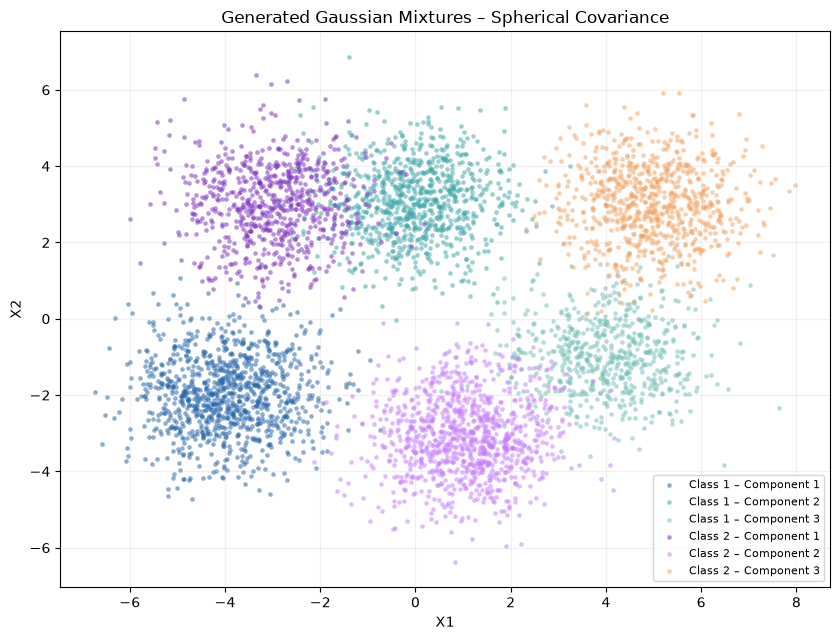

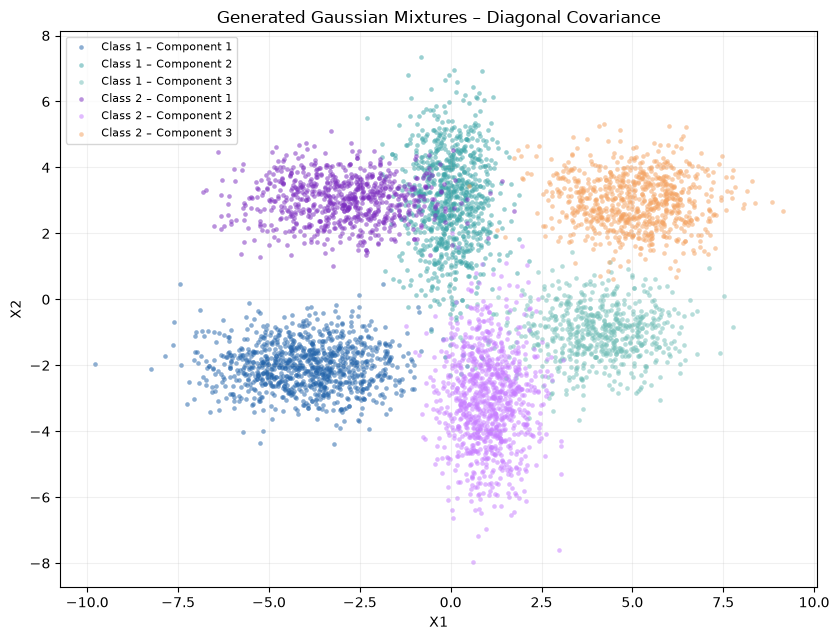

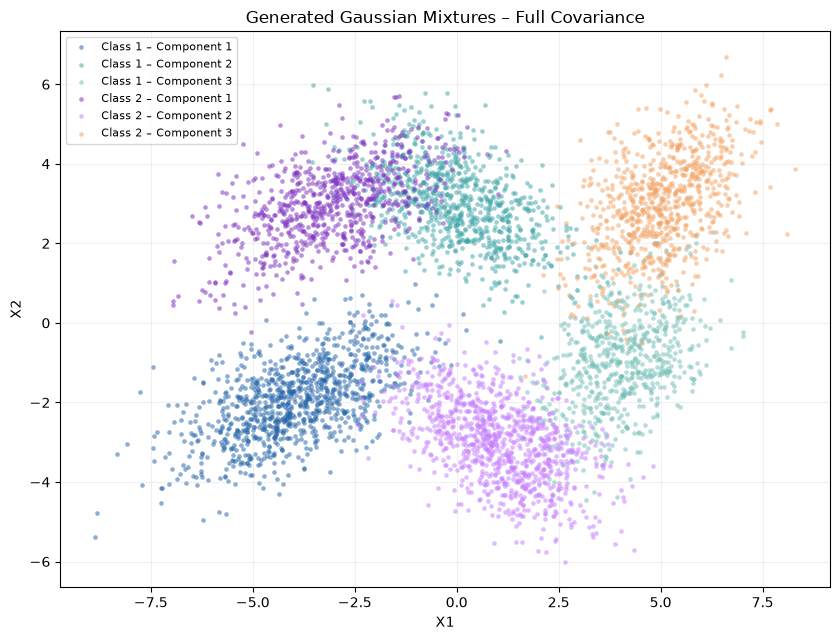

In [4]:
for covariance_name, experiment in generated_experiments.items():
    plt.figure(figsize=(8.5, 6.5))

    for component in range(K):
        points = experiment["class1"][experiment["components1"] == component]
        plt.scatter(
            points[:, 0], points[:, 1],
            s=11, alpha=0.52, linewidths=0,
            color=class_colours[0][component],
            label=f"Class 1 – Component {component + 1}"
        )

    for component in range(K):
        points = experiment["class2"][experiment["components2"] == component]
        plt.scatter(
            points[:, 0], points[:, 1],
            s=11, alpha=0.52, linewidths=0,
            color=class_colours[1][component],
            label=f"Class 2 – Component {component + 1}"
        )

    plt.title(f"Generated Gaussian Mixtures – {covariance_name} Covariance")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend(fontsize=8, frameon=True)
    plt.grid(alpha=0.18)
    plt.tight_layout()
    plt.show()

### 1.2 Deterministic 80/20 train/test split

The generated points are split without shuffling. A fixed modular index ordering interleaves the original sequence, then assigns 80% to training and 20% to testing. The multiplier is chosen to be coprime with the sample count, so every sample index appears exactly once. This avoids all random/shuffle functions while keeping the split reproducible.

In [5]:
def deterministic_split_indices(n, test_fraction=0.20):
    # Create a deterministic permutation using modular arithmetic.
    # The multiplier is selected so it is coprime with n.
    multiplier = max(2, n // 2 + 1)
    while np.gcd(multiplier, n) != 1:
        multiplier += 1

    offset = 37 % n
    base_indices = np.arange(n)
    ordered_indices = (multiplier * base_indices + offset) % n

    test_count = int(round(n * test_fraction))
    test_indices = ordered_indices[:test_count]
    train_indices = ordered_indices[test_count:]
    return train_indices, test_indices

part1_splits = {}

for covariance_name, experiment in generated_experiments.items():
    train_indices, test_indices = deterministic_split_indices(N, 0.20)

    train1 = experiment["class1"][train_indices]
    test1 = experiment["class1"][test_indices]
    train2 = experiment["class2"][train_indices]
    test2 = experiment["class2"][test_indices]

    part1_splits[covariance_name] = {
        "train1": train1, "test1": test1,
        "train2": train2, "test2": test2
    }

    print(
        f"{covariance_name}: "
        f"Class 1 train/test = {len(train1)}/{len(test1)}, "
        f"Class 2 train/test = {len(train2)}/{len(test2)}"
    )

Spherical: Class 1 train/test = 2000/500, Class 2 train/test = 2000/500
Diagonal: Class 1 train/test = 2000/500, Class 2 train/test = 2000/500
Full: Class 1 train/test = 2000/500, Class 2 train/test = 2000/500


### 1.4 Train one GMM for each class

A three-component GMM is fitted to each class's training data using the EM algorithm. Full covariance is used because the generated samples are two-dimensional and the covariance shape/orientation is part of the experiment.

In [6]:
part1_models = {}

for covariance_name, split in part1_splits.items():
    model_class1 = GMM(
        K=K, covariance_type="full", reg=1e-4,
        max_iter=150, tol=1e-4
    )
    model_class2 = GMM(
        K=K, covariance_type="full", reg=1e-4,
        max_iter=150, tol=1e-4
    )

    model_class1.fit(split["train1"])
    model_class2.fit(split["train2"])

    part1_models[covariance_name] = [model_class1, model_class2]

    print(f"\n{covariance_name} covariance")
    print("Class 1 mixture weights:", np.round(model_class1.weights, 4))
    print("Class 2 mixture weights:", np.round(model_class2.weights, 4))
    print("Class 1 EM iterations:", len(model_class1.log_likelihoods))
    print("Class 2 EM iterations:", len(model_class2.log_likelihoods))


Spherical covariance
Class 1 mixture weights: [0.3371 0.2538 0.4091]
Class 2 mixture weights: [0.4025 0.2856 0.312 ]
Class 1 EM iterations: 9
Class 2 EM iterations: 7

Diagonal covariance
Class 1 mixture weights: [0.3487 0.3952 0.2561]
Class 2 mixture weights: [0.3049 0.4013 0.2937]
Class 1 EM iterations: 11
Class 2 EM iterations: 10

Full covariance
Class 1 mixture weights: [0.3349 0.4036 0.2614]
Class 2 mixture weights: [0.305  0.2956 0.3994]
Class 1 EM iterations: 13
Class 2 EM iterations: 10


### 1.4.1 Inspect EM convergence

The plotted values are the mean log-likelihoods recorded at each EM iteration. For a well-behaved fit, the log-likelihood should generally increase and then stabilize.

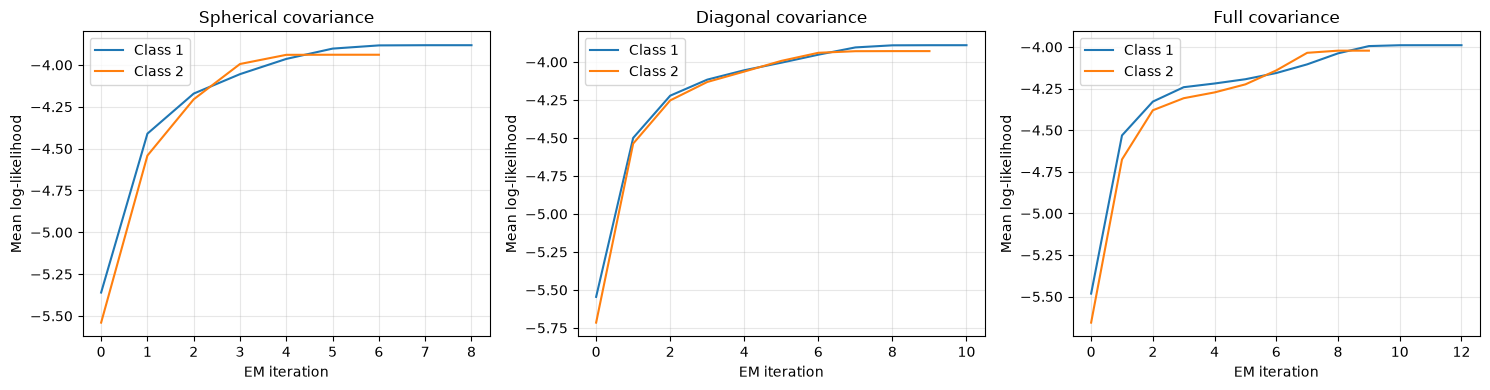

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (covariance_name, models) in zip(axes, part1_models.items()):
    ax.plot(models[0].log_likelihoods, label="Class 1")
    ax.plot(models[1].log_likelihoods, label="Class 2")
    ax.set_title(f"{covariance_name} covariance")
    ax.set_xlabel("EM iteration")
    ax.set_ylabel("Mean log-likelihood")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 1.5 Evaluate the GMM classifiers

For every test point, the two class-conditional log-likelihoods are compared. The class with the larger likelihood is selected. Confusion matrix rows represent actual classes and columns represent predicted classes.

In [8]:
part1_results = {}

for covariance_name, split in part1_splits.items():
    model1, model2 = part1_models[covariance_name]

    test_points = np.vstack((split["test1"], split["test2"]))
    actual_labels = np.array(
        [0] * len(split["test1"]) + [1] * len(split["test2"])
    )

    class_scores = np.column_stack((
        model1.score_samples(test_points),
        model2.score_samples(test_points)
    ))
    predicted_labels = np.argmax(class_scores, axis=1)

    matrix = np.zeros((2, 2), dtype=int)
    for actual, predicted in zip(actual_labels, predicted_labels):
        matrix[actual, predicted] += 1

    accuracy = np.trace(matrix) / np.sum(matrix)

    part1_results[covariance_name] = {
        "confusion": matrix,
        "accuracy": accuracy,
        "actual": actual_labels,
        "predicted": predicted_labels,
        "points": test_points
    }

    print(f"\n{covariance_name} covariance")
    print("Confusion matrix (rows=true, columns=predicted):")
    print(matrix)
    print(f"Accuracy: {accuracy:.2%}")


Spherical covariance
Confusion matrix (rows=true, columns=predicted):
[[473  27]
 [ 18 482]]
Accuracy: 95.50%

Diagonal covariance
Confusion matrix (rows=true, columns=predicted):
[[481  19]
 [ 21 479]]
Accuracy: 96.00%

Full covariance
Confusion matrix (rows=true, columns=predicted):
[[450  50]
 [ 50 450]]
Accuracy: 90.00%


### 1.6 Compare accuracy across covariance experiments

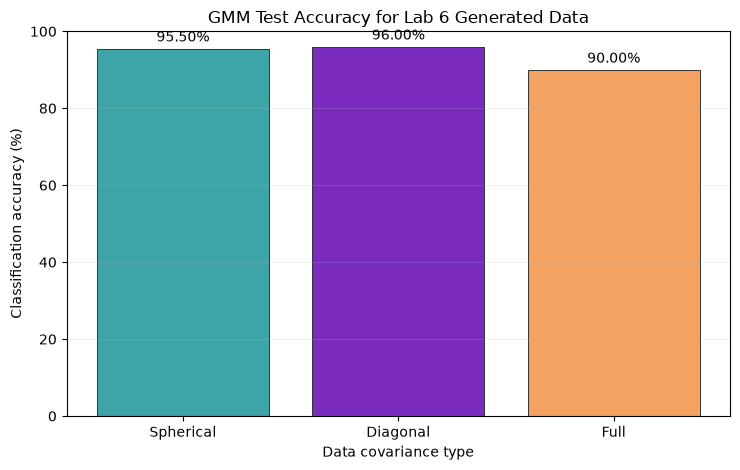

In [9]:
covariance_labels = list(part1_results.keys())
accuracy_values = [
    100 * part1_results[name]["accuracy"] for name in covariance_labels
]

plt.figure(figsize=(7.5, 4.8))
bars = plt.bar(
    covariance_labels, accuracy_values,
    color=["#3DA5A8", "#7B2CBF", "#F4A261"],
    edgecolor="#333333", linewidth=0.7
)
plt.ylabel("Classification accuracy (%)")
plt.xlabel("Data covariance type")
plt.title("GMM Test Accuracy for Lab 6 Generated Data")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)
for bar, value in zip(bars, accuracy_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center", va="bottom"
    )
plt.tight_layout()
plt.show()

### 1.7 Decision boundary for the Full covariance experiment

The zero contour of the difference between the two class log-likelihoods marks the GMM decision boundary.

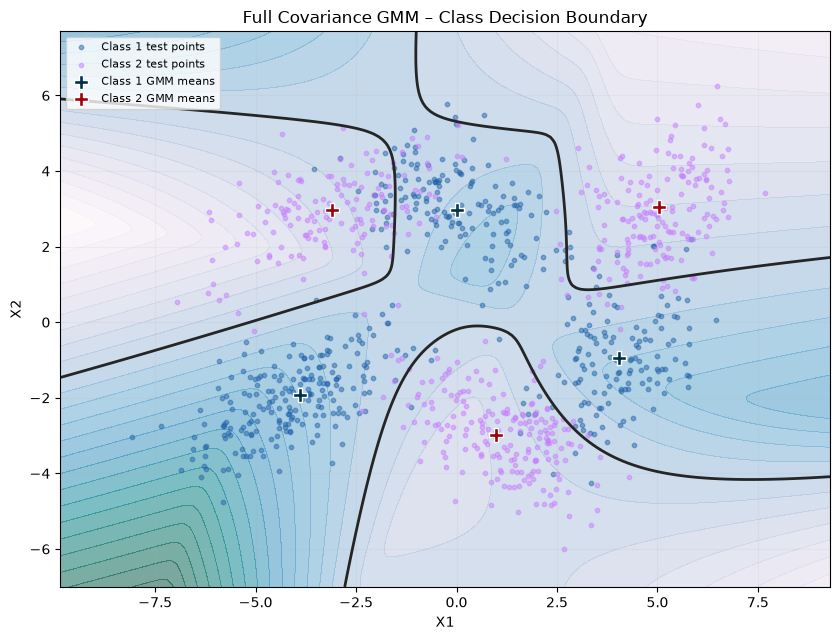

In [10]:
full_split = part1_splits["Full"]
full_model1, full_model2 = part1_models["Full"]

all_points = np.vstack((
    full_split["train1"], full_split["train2"],
    full_split["test1"], full_split["test2"]
))
x_min, y_min = all_points.min(axis=0) - 1
x_max, y_max = all_points.max(axis=0) + 1

grid_x, grid_y = np.meshgrid(
    np.linspace(x_min, x_max, 180),
    np.linspace(y_min, y_max, 180)
)
grid_points = np.column_stack((grid_x.ravel(), grid_y.ravel()))

likelihood_difference = (
    full_model1.score_samples(grid_points) -
    full_model2.score_samples(grid_points)
).reshape(grid_x.shape)

plt.figure(figsize=(8.5, 6.5))
plt.contourf(
    grid_x, grid_y, likelihood_difference,
    levels=28, cmap="PuBuGn", alpha=0.52
)
plt.contour(
    grid_x, grid_y, likelihood_difference,
    levels=[0], colors="#252525", linewidths=2
)
plt.scatter(
    full_split["test1"][:, 0], full_split["test1"][:, 1],
    s=10, alpha=0.48, color="#2364AA", label="Class 1 test points"
)
plt.scatter(
    full_split["test2"][:, 0], full_split["test2"][:, 1],
    s=10, alpha=0.48, color="#C77DFF", label="Class 2 test points"
)
plt.scatter(
    full_model1.means[:, 0], full_model1.means[:, 1],
    marker="P", s=100, color="#003049", edgecolor="white",
    label="Class 1 GMM means"
)
plt.scatter(
    full_model2.means[:, 0], full_model2.means[:, 1],
    marker="P", s=100, color="#9D0208", edgecolor="white",
    label="Class 2 GMM means"
)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Full Covariance GMM – Class Decision Boundary")
plt.legend(fontsize=8)
plt.grid(alpha=0.12)
plt.tight_layout()
plt.show()

## Part 2 – Classification of the existing digit datasets (0, 1 and 4)



### 2.1 Load the existing images

In [11]:
digits = [0, 1, 4]
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def load_digit_images(split_name):
    split_path = DATA_DIR / split_name
    images_by_digit = {}

    for digit in digits:
        digit_path = split_path / str(digit)
        if not digit_path.is_dir():
            raise FileNotFoundError(
                f"Missing folder: {digit_path}. Expected data/{split_name}/{digit}/"
            )

        image_paths = sorted(
            path for path in digit_path.iterdir()
            if path.is_file() and path.suffix.lower() in image_extensions
        )
        if not image_paths:
            raise FileNotFoundError(f"No image files found in {digit_path}")

        digit_images = []
        for image_path in image_paths:
            with Image.open(image_path) as image:
                gray_image = image.convert("L")
                if gray_image.size != (28, 28):
                    raise ValueError(
                        f"{image_path} has size {gray_image.size}; "
                        "this notebook currently expects 28x28 MNIST images."
                    )
                digit_images.append(
                    np.asarray(gray_image, dtype=np.float32) / 255.0
                )

        images_by_digit[digit] = np.stack(digit_images)

    return images_by_digit

train_images = load_digit_images("train")
dev_images = load_digit_images("dev")

for digit in digits:
    print(
        f"Digit {digit}: "
        f"train={train_images[digit].shape}, "
        f"dev={dev_images[digit].shape}"
    )

Digit 0: train=(4735, 28, 28), dev=(1188, 28, 28)
Digit 1: train=(5383, 28, 28), dev=(1359, 28, 28)
Digit 4: train=(4681, 28, 28), dev=(1161, 28, 28)


### 2.2 Flatten images and reduce dimensions using PCA

Each 28 × 28 image is first flattened into 784 pixel values. PCA is fitted **only on the training data** and retains 40 principal components. The same training mean and projection are then applied to the development and test data to avoid information leakage.

Original feature dimensions: 784
PCA feature dimensions: 40
Variance retained by PCA: 85.18%


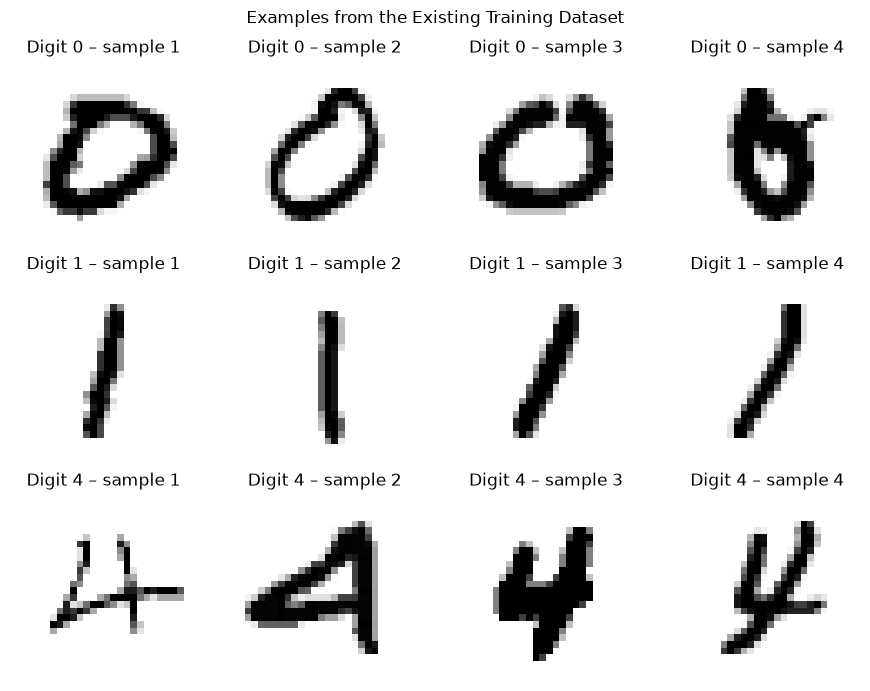

In [12]:
train_flat = {
    digit: train_images[digit].reshape(len(train_images[digit]), -1)
    for digit in digits
}
dev_flat = {
    digit: dev_images[digit].reshape(len(dev_images[digit]), -1)
    for digit in digits
}

# Combine only training images to learn the PCA transformation.
X_train_all = np.vstack([train_flat[d] for d in digits])
pca_mean = X_train_all.mean(axis=0)
X_centered = X_train_all - pca_mean

# Eigen-decomposition of the training covariance matrix.
covariance_matrix = np.cov(X_centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
order = np.argsort(eigenvalues)[::-1]
PCA_DIMENSIONS = 40
pca_projection = eigenvectors[:, order[:PCA_DIMENSIONS]]

train_features = {
    d: (train_flat[d] - pca_mean) @ pca_projection for d in digits
}
dev_features = {
    d: (dev_flat[d] - pca_mean) @ pca_projection for d in digits
}

explained = np.sum(eigenvalues[order[:PCA_DIMENSIONS]]) / np.sum(eigenvalues)
print("Original feature dimensions: 784")
print("PCA feature dimensions:", PCA_DIMENSIONS)
print(f"Variance retained by PCA: {explained:.2%}")

fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for row, digit in enumerate(digits):
    for column in range(4):
        axes[row, column].imshow(
            train_images[digit][column], cmap="gray_r", vmin=0, vmax=1
        )
        axes[row, column].set_title(f"Digit {digit} – sample {column + 1}")
        axes[row, column].axis("off")
plt.suptitle("Examples from the Existing Training Dataset")
plt.tight_layout()
plt.show()

### 2.3 Select the number of Gaussian components using development data

Candidate values K = 3, 5, and 8 are tested. Each class GMM is trained on its PCA-transformed training images using full covariance matrices. Development accuracy selects K; test data is not used during model selection.

In [ ]:
candidate_K_values = [3, 5, 8]
dev_scores = []
best_dev_accuracy = -1
best_K = None
best_digit_models = None

# Class priors are estimated from training-set class counts.
train_counts = np.array([len(train_features[d]) for d in digits], dtype=float)
class_priors = train_counts / train_counts.sum()

for candidate_K in candidate_K_values:
    candidate_models = []
    for digit in digits:
        model = GMM(
            K=candidate_K, covariance_type="full",
            reg=1e-3, max_iter=150, tol=1e-4
        )
        model.fit(train_features[digit])
        candidate_models.append(model)

    confusion_dev = np.zeros((len(digits), len(digits)), dtype=int)
    for true_index, digit in enumerate(digits):
        samples = dev_features[digit]
        likelihoods = np.column_stack([
            model.score_samples(samples) + math.log(class_priors[j])
            for j, model in enumerate(candidate_models)
        ])
        predicted_indices = np.argmax(likelihoods, axis=1)
        for predicted_index in predicted_indices:
            confusion_dev[true_index, predicted_index] += 1

    accuracy_dev = np.trace(confusion_dev) / confusion_dev.sum()
    dev_scores.append(accuracy_dev)
    print(f"Candidate K={candidate_K}")
    print("Development confusion matrix:")
    print(confusion_dev)
    print(f"Development accuracy: {accuracy_dev:.2%}\n")

    if accuracy_dev > best_dev_accuracy:
        best_dev_accuracy = accuracy_dev
        best_K = candidate_K
        best_digit_models = candidate_models

print("Selected component count:", best_K)
print(f"Best development accuracy: {best_dev_accuracy:.2%}")

Candidate K=3
Development confusion matrix:
[[1182    0    6]
 [   5 1329   25]
 [   3    1 1157]]
Development accuracy: 98.92%

Candidate K=5
Development confusion matrix:
[[1183    0    5]
 [   3 1325   31]
 [   3    1 1157]]
Development accuracy: 98.84%

Candidate K=8
Development confusion matrix:
[[1187    0    1]
 [   2 1319   38]
 [   3    1 1157]]
Development accuracy: 98.79%

Selected component count: 3
Best development accuracy: 98.92%


### 2.4 Compare development accuracy for the candidate K values

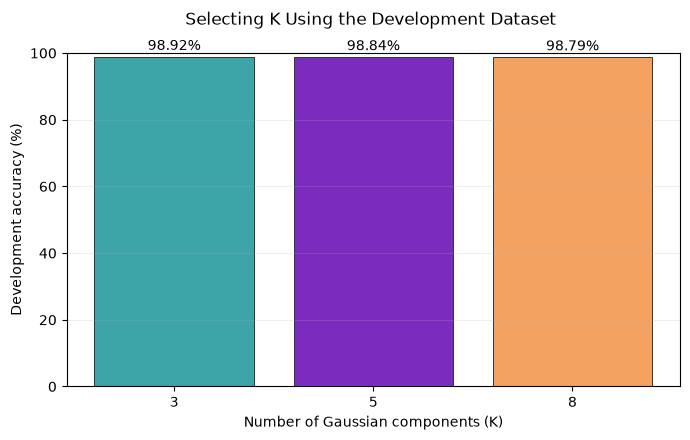

In [21]:
plt.figure(figsize=(7, 4.5))
bars = plt.bar(
    [str(k) for k in candidate_K_values],
    [score * 100 for score in dev_scores],
    color=["#3DA5A8", "#7B2CBF", "#F4A261"],
    edgecolor="#333333", linewidth=0.7
)
plt.xlabel("Number of Gaussian components (K)")
plt.ylabel("Development accuracy (%)")
plt.title("Selecting K Using the Development Dataset \n")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)
for bar, score in zip(bars, dev_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2%}",
        ha="center", va="bottom"
    )
plt.tight_layout()
plt.show()

### 2.5 Visualize the learned Gaussian component means

Each GMM mean is in 40-dimensional PCA space. To visualize it as an image, the PCA projection is reversed approximately and the training mean image is added back. These are reconstructed component mean patterns, not necessarily actual handwritten examples.

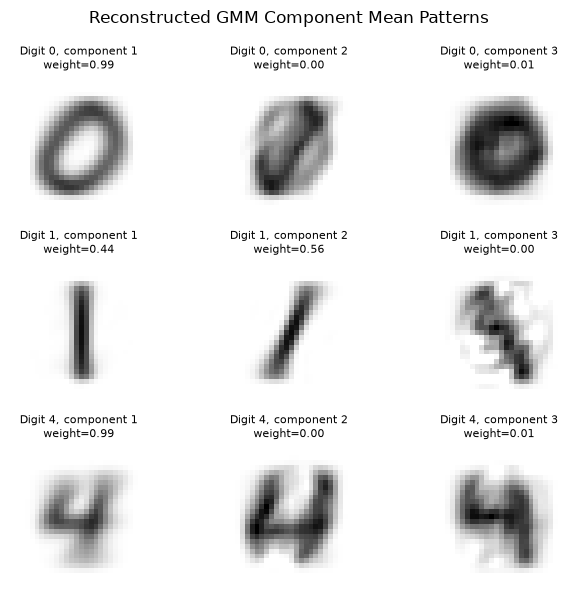

In [15]:
fig, axes = plt.subplots(len(digits), best_K, figsize=(2.2 * best_K, 6))
if best_K == 1:
    axes = axes.reshape(len(digits), 1)

for row, (digit, model) in enumerate(zip(digits, best_digit_models)):
    for component in range(best_K):
        reconstructed = model.means[component] @ pca_projection.T + pca_mean
        reconstructed = np.clip(reconstructed.reshape(28, 28), 0, 1)
        axes[row, component].imshow(reconstructed, cmap="gray_r", vmin=0, vmax=1)
        axes[row, component].set_title(
            f"Digit {digit}, component {component + 1}\n"
            f"weight={model.weights[component]:.2f}",
            fontsize=8
        )
        axes[row, component].axis("off")
plt.suptitle("Reconstructed GMM Component Mean Patterns")
plt.tight_layout()
plt.show()

### 2.6 Evaluate the selected models on the held-out test data

The test data is loaded only after selecting K. It is not used to train the GMMs or select the component count.

In [16]:
test_images = load_digit_images("test")
test_flat = {
    digit: test_images[digit].reshape(len(test_images[digit]), -1)
    for digit in digits
}
test_features = {
    d: (test_flat[d] - pca_mean) @ pca_projection for d in digits
}

test_confusion = np.zeros((len(digits), len(digits)), dtype=int)
test_predictions = {}
test_scores_by_true_digit = {}

for true_index, digit in enumerate(digits):
    samples = test_features[digit]
    likelihoods = np.column_stack([
        model.score_samples(samples) + math.log(class_priors[j])
        for j, model in enumerate(best_digit_models)
    ])
    predicted_indices = np.argmax(likelihoods, axis=1)
    test_predictions[digit] = predicted_indices
    test_scores_by_true_digit[digit] = likelihoods

    for predicted_index in predicted_indices:
        test_confusion[true_index, predicted_index] += 1

test_accuracy = np.trace(test_confusion) / test_confusion.sum()
print("Digit order:", digits)
print("Test confusion matrix (rows=true, columns=predicted):")
print(test_confusion)
print(f"Overall test accuracy: {test_accuracy:.2%}")
for index, digit in enumerate(digits):
    total = test_confusion[index].sum()
    recall = test_confusion[index, index] / total if total else 0
    print(f"Digit {digit} recall: {recall:.2%} ({test_confusion[index, index]}/{total})")

Digit order: [0, 1, 4]
Test confusion matrix (rows=true, columns=predicted):
[[ 980    0    0]
 [   3 1120   12]
 [   2    0  980]]
Overall test accuracy: 99.45%
Digit 0 recall: 100.00% (980/980)
Digit 1 recall: 98.68% (1120/1135)
Digit 4 recall: 99.80% (980/982)


### 2.7 Plot the final test confusion matrix

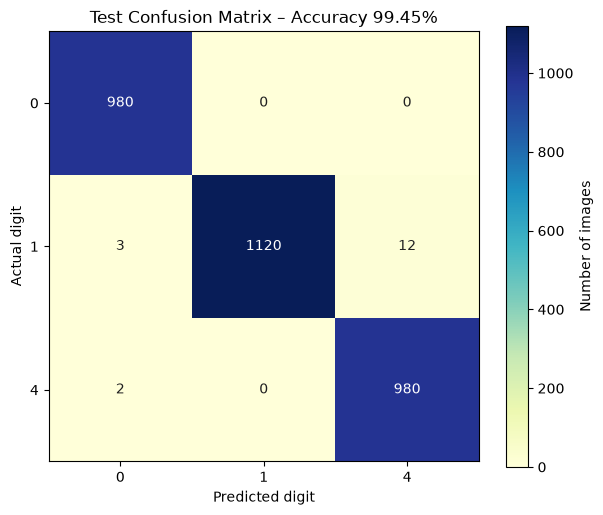

In [17]:
plt.figure(figsize=(6.2, 5.2))
plt.imshow(test_confusion, cmap="YlGnBu")
plt.xticks(range(len(digits)), digits)
plt.yticks(range(len(digits)), digits)
for row in range(len(digits)):
    for column in range(len(digits)):
        value = test_confusion[row, column]
        plt.text(
            column, row, str(value),
            ha="center", va="center",
            color="white" if value > test_confusion.max() * 0.55 else "#202020"
        )
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title(f"Test Confusion Matrix – Accuracy {test_accuracy:.2%}")
plt.colorbar(label="Number of images")
plt.tight_layout()
plt.show()

### 2.7.1 Inspect EM convergence for the selected digit models

This plot shows how the mean log-likelihood changes during EM for each selected class model.

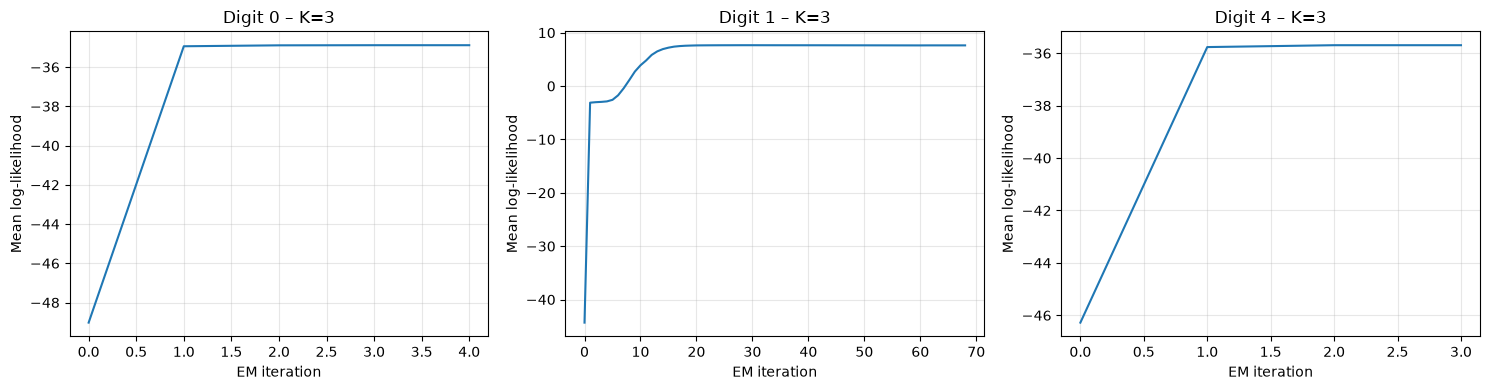

In [18]:
fig, axes = plt.subplots(1, len(digits), figsize=(15, 4))
for ax, digit, model in zip(axes, digits, best_digit_models):
    ax.plot(model.log_likelihoods)
    ax.set_title(f"Digit {digit} – K={best_K}")
    ax.set_xlabel("EM iteration")
    ax.set_ylabel("Mean log-likelihood")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.8 Pairwise class-boundary analysis using log-likelihood ratios



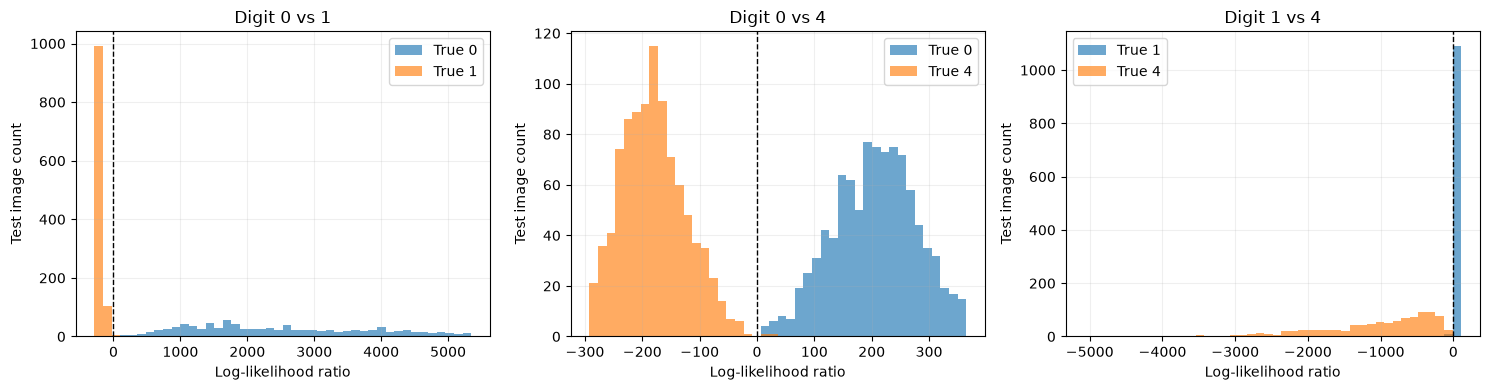

In [19]:
# Combine test samples and labels in the original digit order.
X_test_all = np.vstack([test_features[d] for d in digits])
y_test_all = np.concatenate([
    np.full(len(test_features[d]), i, dtype=int)
    for i, d in enumerate(digits)
])
all_test_scores = np.column_stack([
    model.score_samples(X_test_all) + math.log(class_priors[j])
    for j, model in enumerate(best_digit_models)
])

pairs = [(0, 1), (0, 2), (1, 2)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (a, b) in zip(axes, pairs):
    llr = all_test_scores[:, a] - all_test_scores[:, b]
    bins = np.linspace(np.percentile(llr, 1), np.percentile(llr, 99), 45)
    ax.hist(llr[y_test_all == a], bins=bins, alpha=0.65, label=f"True {digits[a]}")
    ax.hist(llr[y_test_all == b], bins=bins, alpha=0.65, label=f"True {digits[b]}")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Digit {digits[a]} vs {digits[b]}")
    ax.set_xlabel("Log-likelihood ratio")
    ax.set_ylabel("Test image count")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2.9 Inspect misclassified test images


Actual 1 predicted as 0: 3 images
Actual 1 predicted as 4: 12 images
Actual 4 predicted as 0: 2 images


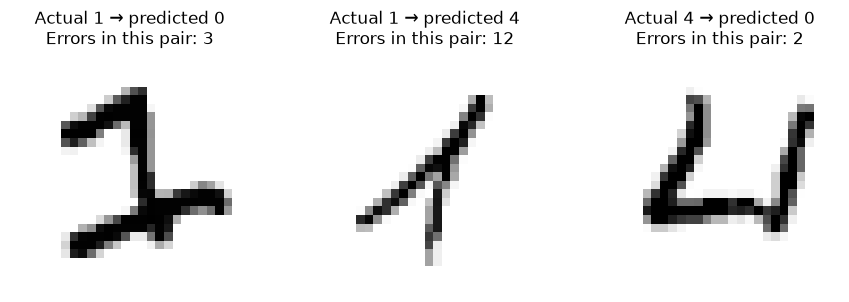

In [20]:
error_examples = []

for true_index, true_digit in enumerate(digits):
    predictions = test_predictions[true_digit]

    for predicted_index, predicted_digit in enumerate(digits):
        if predicted_index == true_index:
            continue

        wrong_indices = np.where(predictions == predicted_index)[0]
        if len(wrong_indices) > 0:
            error_examples.append((
                true_digit, predicted_digit, int(wrong_indices[0]), len(wrong_indices)
            ))
            print(
                f"Actual {true_digit} predicted as {predicted_digit}: "
                f"{len(wrong_indices)} images"
            )

if error_examples:
    column_count = min(4, len(error_examples))
    row_count = (len(error_examples) + column_count - 1) // column_count
    fig, axes = plt.subplots(
        row_count, column_count,
        figsize=(3 * column_count, 3 * row_count)
    )
    axes = np.asarray(axes).reshape(-1)

    for ax, (true_digit, predicted_digit, image_index, count) in zip(
            axes, error_examples):
        ax.imshow(
            test_images[true_digit][image_index],
            cmap="gray_r", vmin=0, vmax=1
        )
        ax.set_title(
            f"Actual {true_digit} → predicted {predicted_digit}\n"
            f"Errors in this pair: {count}"
        )
        ax.axis("off")

    for ax in axes[len(error_examples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test images were found.")